In [193]:
%load_ext autoreload
%autoreload 2

# Add project source directory to import path.
import sys
import os
from pathlib import Path

parent_dir = str(os.path.join(Path.cwd().parent, 'src'))

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

# Imports.
from typing import cast
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
import fvopn_simulations as fvopn

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [267]:
rng = np.random.default_rng(42)
alpha = 5 # Root slots.
k = 20 # Multiplication factor.
size = 1000 # Number of nodes.
levels = math.ceil(math.log(size * (k - 1) / alpha + 1, k))
budgets=rng.beta(.5, 8, size) # Random generated budgets.
cost_fn = lambda b, sel, m: min(b[sel, 2][0], b[:, 2][0].sum() * (1 / b[sel, 1][0]))
                    

conf = fvopn.VoteAuctionModelV2Config(
    budgets=budgets,
    root_slots=alpha,
    multiplication_factor=k,
    cost=cost_fn,
)

model = fvopn.VoteAuctionModelV2(conf, rng)

In [ ]:
def graph_fn(fn):
    fn_vec = np.vectorize(fn)

    xpoints = np.arange(1, 50)
    ypoints = fn_vec(xpoints)

    # Create the spline object
    spline_obj = make_interp_spline(xpoints, ypoints)

    # Evaluate at new points
    x_smooth = np.linspace(xpoints.min(), xpoints.max(), 150)
    y_smooth = spline_obj(x_smooth)

    return (x_smooth, y_smooth)

In [264]:
def V(whale_budget: float, x: int):
    b = np.copy(budgets)

    b[x:2*x] = whale_budget / x

    b[0:x] = whale_budget / x
    
    conf = fvopn.VoteAuctionModelV2Config(
        budgets=b,
        root_slots=alpha,
        multiplication_factor=k,
        cost=None
    )

    model = fvopn.VoteAuctionModelV2(conf, rng)

    res = 0

    N = 1
    
    for _ in range(N):
        a = model.run()

        a = a.sort_index()
        
        res += a.loc[0:x, 'votes'].sum()

    res /= N

    return res

In [268]:
V(1, 1)

np.float64(0.03101497411848219)

In [282]:
x1, y1 = graph_fn(lambda x: V(np.max(budgets[x:]), x))
x2, y2 = graph_fn(lambda x: V(np.max(budgets[x:])*2, x))
x3, y3 = graph_fn(lambda x: V(np.max(budgets[x:])*3, x))
x4, y4 = graph_fn(lambda x: V(np.max(budgets[x:])*4, x))

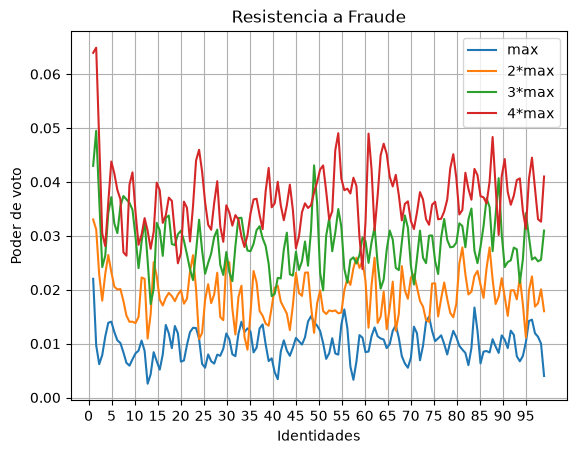

In [283]:
plt.plot(x1, y1, label="max")
plt.plot(x2, y2, label="2*max")
plt.plot(x3, y3, label="3*max")
plt.plot(x4, y4, label="4*max")
plt.xticks(np.arange(0, 100, 5))
plt.title("Resistencia a Fraude")
plt.xlabel("Identidades")
plt.ylabel("Poder de voto")
plt.grid()
plt.legend()
plt.show()